## Perceptron

#### add libs

In [131]:
!uv add numpy
!uv add pandas
!uv add matplotlib

Resolved 20 packages in 2ms
Audited 19 packages in 0.42ms
Resolved 20 packages in 2ms
Audited 19 packages in 0.29ms
Resolved 20 packages in 2ms
Audited 19 packages in 0.32ms


#### add required libs

In [132]:
import numpy as np
import matplotlib.pyplot as plt

#### Generate random data 

In [133]:
n_samples=50
np.random.seed(42)
x1_cats = np.random.uniform(0, 5, n_samples)
x2_cats = np.random.uniform(0, 5, n_samples)
y_cats = np.ones(n_samples) * -1  # Class label -1 for cats


x1_dogs=np.random.uniform(4,8,n_samples)
x2_dogs=np.random.uniform(4,8,n_samples)
y_dogs=np.ones(n_samples)  # Class label 1 for dogs


cats_stack=np.stack([np.ones(n_samples),x1_cats,x2_cats,y_cats],axis=1)
dogs_stack=np.stack([np.ones(n_samples),x1_dogs,x2_dogs,y_dogs],axis=1)
data=np.concatenate([cats_stack,dogs_stack],axis=0) # x1,x2,y

shuffled_data=data[np.random.permutation(n_samples*2)]


x=shuffled_data[:,:-1]
y=shuffled_data[:,-1]

In [134]:
w0,w1,w2=np.random.randn(3)
print(f"Initional Wights w0={w0} , w1={w1} , w2={w2}")
epchos=1000
eta=.02
errors=[]

Initional Wights w0=0.5150476863060478 , w1=3.8527314906547208 , w2=0.570890510693167


#### Learning

In [135]:
for i in range(epchos):
    error=0
    
    for j in range(len(x)):    # loop over dataset
        xj=x[j]
        yj=y[j]
        z = w0*xj[0] + w1*xj[1]+ w2*xj[2]
        
        yhat=1 if z>=0 else -1   # y predict equal any of [1,-1]  [dog,cat]
        
        if yhat!=yj:
            w0=w0- eta*(yhat -yj)*xj[0]
            w1=w1- eta*(yhat -yj)*xj[1]
            w2=w2- eta*(yhat -yj)*xj[2]
            
            
            error+=1
            
    errors.append(error)         
        
    if error==0:
        break    
        
        

In [136]:
print(f"Final Wights w0={w0} , w1={w1} , w2={w2} at epcho ={i}")


Final Wights w0=-1.1249523136939525 , w1=0.15013983177408463 , w2=0.09451643517665118 at epcho =3


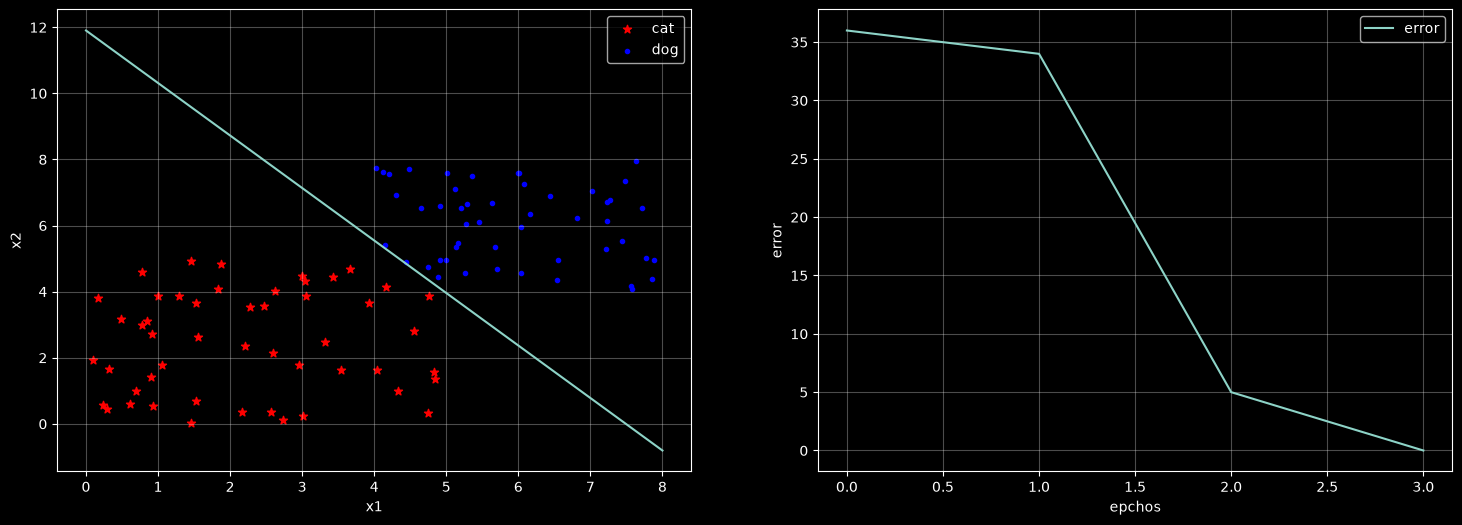

In [137]:
plt.style.use("dark_background")
plt.figure(figsize=(18,6))
plt.subplot(1,2,1)
plt.grid(alpha=.3)
plt.scatter(x1_cats,x2_cats,marker="*",color="red",label="cat")
plt.scatter(x1_dogs,x2_dogs,marker=".",color="blue",label="dog")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()


# z=w0*x0 + w1*x1 + w2*x2 
# w0*x0 + w1*x1 + w2*x2 = 0
# w2*x2 = -(w0*x0 + w1*x1)
# x2 = -(w0*x0 + w1*x1) / w2
# x2 = -(w0 + w1*x1) / w2


lx=np.linspace(0,8,100)
ly=-(w0 + w1*lx) / w2

plt.plot(lx,ly,label="line")

plt.subplot(1,2,2)
plt.grid(alpha=.3)
plt.plot(errors,label="error")
plt.xlabel("epchos")
plt.ylabel("error")
plt.legend()
plt.show()

In [138]:
predicions= (x[:,0]*w0) + (x[:,1]*w1) + (x[:,2]*w2)
predicions=np.where(predicions>=0,1,-1)
accuracy=np.mean(predicions==y)
print(f'Accuracy: {accuracy * 100:0.2f}%')

Accuracy: 100.00%
